# 02 — Pixels, amostragem e quantização

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 02/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** As células principais usam dados sintéticos ou conjuntos fornecidos pelas bibliotecas. Dependências adicionais só são necessárias nos laboratórios explicitamente opcionais.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 02/16

> **Execução:** células principais executadas localmente no JupyterLab em 14/11/2026, conforme confirmação do autor.


### Materiais complementares

- [Guia Técnico](./reference_materials/02_pixels_amostragem_quantizacao.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_pixels_amostragem_quantizacao.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Explicar resolução espacial, quantização e conversão de tipos sem perda acidental.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

A amostragem transforma uma cena contínua em uma grade. A quantização limita níveis de intensidade. Reduzir resolução pode causar aliasing; filtrar antes de subamostrar ajuda. `uint8` representa 0–255, enquanto operações em ponto flutuante frequentemente utilizam 0–1. Conversões mal controladas saturam ou truncam valores.

### Conceito matemático

$$L=2^b$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
import numpy as np
from skimage.data import camera
from skimage.transform import resize
im=camera().astype(np.float32)/255
small=resize(im,(64,64),anti_aliasing=True)
back=resize(small,im.shape,anti_aliasing=False)
print('original',im.shape,'reduzida',small.shape,'MSE reconstrução',round(np.mean((im-back)**2),5))

original (512, 512) reduzida (64, 64) MSE reconstrução 0.00568


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

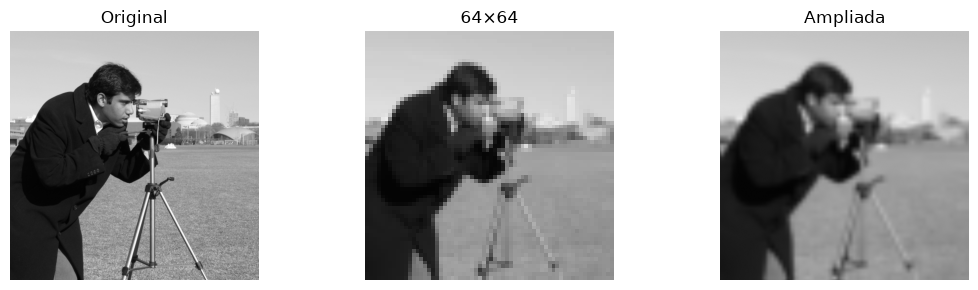

In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,3,figsize=(11,3))
for a,img,t in zip(ax,[im,small,back],['Original','64×64','Ampliada']):a.imshow(img,cmap='gray',vmin=0,vmax=1);a.set_title(t);a.axis('off')
plt.tight_layout();plt.show()

## Interpretação técnica

Ampliação não recupera detalhes perdidos; ela interpola valores.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** Quantos níveis de cinza podem ser representados por 8 bits?

**Resolução comentada:** 256 níveis discretos, de 0 até 255.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Erros comuns e limitações

`resize` não é evidência de reconstrução fiel: não confunda interpolação com informação recuperada.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Explicar resolução espacial, quantização e conversão de tipos sem perda acidental.
- **Mecanismo:** A amostragem transforma uma cena contínua em uma grade.
- **Equação:** $L=2^b$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** resolução e quantização. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **resolução e quantização** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **resolução e quantização** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
